# 06 · Transformer desde cero

**Objetivo:** construir, entrenar y evaluar un **encoder Transformer pequeño, desde cero**, y medir con honestidad cuánto se acerca a:
- la **CNN de caracteres** del `05`: 0.765 ± 0.024, `V1__nn_cnn_char__tune-d0.3-lr0.002`;
- el **mejor lineal**: V2 + regresión logística elasticnet ajustada, 0.794 ± 0.022 en los folds principales y 0.786 en `folds_seed2`.

**Es un experimento acotado: no esperamos ganar.** Los Transformers brillan cuando se preentrenan con millones de textos. Aquí todo se entrena con ≈1.4k tuits por fold, que es muy poco para aprender buenas representaciones. Mediremos cuánto se acerca, qué decisiones importan y si se equivoca en tuits distintos a los demás modelos, por si aporta diversidad al ensamble del `07`.

**Conceptos:**
- **Encoder (Transformer):** red que transforma una secuencia de tokens en una secuencia de vectores, donde cada vector "ha mirado" a todos los demás tokens del texto.
- **Autoatención:** el mecanismo con el que cada token calcula cuánto debe fijarse en cada uno de los otros (los pesos de atención suman 1) y mezcla sus representaciones según esos pesos.
- **Cabezas de atención:** varias autoatenciones en paralelo (aquí 4), cada una con sus propios pesos, de modo que cada una puede fijarse en relaciones distintas.
- **Posiciones aprendidas:** la autoatención no sabe en qué orden van los tokens, así que a cada posición (1.ª, 2.ª, …) se le suma un vector propio que se aprende.
- **Pre-LayerNorm:** normalizar las activaciones *antes* de cada subcapa (atención y red densa). Es más estable que hacerlo después cuando la red es pequeña y los datos pocos.
- **Warmup:** empezar con una tasa de aprendizaje casi nula y subirla poco a poco durante el 10% inicial del entrenamiento; después baja linealmente. Evita pasos bruscos al principio, cuando los pesos son aleatorios.
- **BPE (*byte pair encoding*):** tokenizador que parte de caracteres y une repetidamente los pares más frecuentes hasta tener un vocabulario del tamaño pedido (800 o 2000). Así las palabras comunes quedan como un solo token y las raras se parten en trozos (*cllate* → *c* + *llate*).
- **Pooling:** cómo resumir la secuencia en un solo vector para clasificar: la **media** de los vectores de los tokens (ignorando el relleno) o el vector de un token especial **[CLS]** que va al principio.
- **MLM (*masked language modeling*):** preentrenamiento sin etiquetas. Se ocultan al azar el 15% de los tokens y la red aprende a adivinarlos por el contexto; después se ajusta con las etiquetas.

**Reglas:**
- Nada preentrenado: la arquitectura es `torch.nn` con pesos aleatorios, y no se usa la librería `transformers`, `from_pretrained` ni la descarga de pesos.
- El BPE se entrena aquí con la librería `tokenizers` (solo su entrenador).
- El vocabulario, el BPE y el MLM se ajustan **dentro de cada fold** con el texto de ese fold, sin el test ni corpus externos (P13 sigue abierta).
- El early stopping usa una validación interna del 12%, nunca el fold externo.
- Al final se comprueba con `grep` que no aparece ninguna carga de modelos preentrenados.

**Ejecución y reanudación:**
- `RECOMPUTE = False` (valor por defecto) reutiliza la caché por configuración y fold (`models/06_transformer/cache/`) y solo entrena lo que falte. Si la caché está completa, el notebook se ejecuta en minutos.
- `RECOMPUTE = True` borra la caché y reentrena todo (≈2 h en CPU). También se puede activar sin editar el notebook, con la variable de entorno `TWEETTOXIC_RECOMPUTE=1`.
- Cada fold se guarda en disco en cuanto termina: si la ejecución se interrumpe, al volver a lanzarla con `RECOMPUTE = False` continúa donde se quedó.
- El detalle del entrenamiento (épocas, mejor época y tiempo por semilla) se escribe en `models/06_transformer/train.log`.
- Para ejecutarlo en segundo plano:

  ```bash
  nohup uv run jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 \
        notebooks/06_transformer_desde_cero.ipynb > models/06_transformer/run.log 2>&1 &
  tail -f models/06_transformer/train.log
  ```

## 1. Configuración

In [1]:
import importlib.util
import json
import os
import platform
import re
import subprocess
import time
import warnings

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tokenizers
import torch
from IPython.display import display

import modeling as md
import neural as nn_
import preprocessing as pp
from common import FIGURES_DIR, LABELS, NOTEBOOKS_DIR, PROCESSED_DIR, SEED, load_test, load_train, make_folds

RECOMPUTE = False  # True: borra la caché y reentrena todo (≈3 h). False: reutiliza la caché y entrena solo lo que falte
RECOMPUTE = RECOMPUTE or os.environ.get("TWEETTOXIC_RECOMPUTE") == "1"

warnings.filterwarnings("ignore", category=UserWarning, module="torch")
nn_.set_seed(SEED)
sklearn.set_config(display="text")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 200)
N_JOBS, FOLD_THREADS, FINAL_THREADS = 5, 2, 8
OUT_DIR = md.model_folder("06")
CACHE_DIR = OUT_DIR / "cache"
LOG_PATH = OUT_DIR / "train.log"
TOK_COLORS = {"char": "#4a3aa7", "bpe800": "#1baf7a", "bpe2000": "#eb6834"}


def savefig(fig, name):
    fig.savefig(FIGURES_DIR / f"06_{name}.png", dpi=120, bbox_inches="tight")


print(f"Python {platform.python_version()} | torch {torch.__version__} | tokenizers {tokenizers.__version__} | "
      f"scikit-learn {sklearn.__version__} | SEED = {SEED} | RECOMPUTE = {RECOMPUTE}")
print(f"GPU CUDA: {torch.cuda.is_available()} | Apple MPS: {torch.backends.mps.is_available()} -> se entrena en CPU "
      f"({N_JOBS} folds en paralelo × {FOLD_THREADS} hilos)")
print("Librería `transformers` instalada:", importlib.util.find_spec("transformers") is not None)
train = load_train()
test = load_test()
Y = train[LABELS].to_numpy()
texts = train["text"]
folds = make_folds(train)
folds2 = make_folds(train, seed=SEED + 1, path=PROCESSED_DIR / "folds_seed2.csv")
pp.load_lemma_cache(PROCESSED_DIR / "lemma_cache.parquet")
with open(LOG_PATH, "a") as f:
    f.write(f"\n===== {time.strftime('%Y-%m-%d %H:%M:%S')} inicio del 06 (RECOMPUTE={RECOMPUTE}) =====\n")

Python 3.14.6 | torch 2.14.1 | tokenizers 0.23.3 | scikit-learn 1.9.1 | SEED = 42 | RECOMPUTE = False
GPU CUDA: False | Apple MPS: True -> se entrena en CPU (5 folds en paralelo × 2 hilos)
Librería `transformers` instalada: False


### Referencias (leídas de las predicciones OOF guardadas, sin reentrenar)

Las comparaciones son pareadas por fold contra dos referencias:
- **(i)** la CNN de caracteres del `05`;
- **(ii)** el mejor lineal del `04`.

Se considera **empate** si |media de Δ| < desviación de Δ entre folds. No se elige nada por diferencias dentro del ruido.

In [2]:
oof_store = pd.read_parquet(md.OOF_PATH)


def stored_cv(model_id, f=folds):
    oof = oof_store[oof_store["model_id"] == model_id].set_index("id").loc[train["id"], [f"p_{l}" for l in LABELS]].to_numpy()
    at_05, tuned = md._summarize_folds(oof, Y, f)
    return {"oof": oof, "at_05": at_05, "tuned": tuned}


REF_LIN, REF_CNN = "V2__logreg__nested", "V1__nn_cnn_char__tune-d0.3-lr0.002"
REFS = {m: stored_cv(m) for m in [REF_LIN, REF_CNN, "V3__linsvm"]}
for k, r in REFS.items():
    print(f"{k}: F1 macro ajustado {r['tuned']['F1_macro'].mean():.4f} ± {r['tuned']['F1_macro'].std():.4f}")

V2__logreg__nested: F1 macro ajustado 0.7937 ± 0.0216
V1__nn_cnn_char__tune-d0.3-lr0.002: F1 macro ajustado 0.7654 ± 0.0243
V3__linsvm: F1 macro ajustado 0.7817 ± 0.0160


## 2. Presupuesto de tiempo y plan

Antes de entrenar medimos cuánto tarda **una época** de cada configuración del cribado (un fold, una semilla, 2 hilos). Para la más cara medimos además **un fold completo con una semilla**. Con esos tiempos se estima cada sección. En la caché se guarda la medición de la primera ejecución, para que el plan se lea igual al reproducir el notebook.

**Plan (diseño por etapas, 10 configuraciones como máximo, todas con 3 semillas por fold):**

| Etapa | Qué se prueba | Variantes | Ejecuciones |
|---|---|---|---|
| 1. Cribado | tokenización {caracteres, BPE-800, BPE-2000} × tamaño {d_model 64 y 1 capa, d_model 128 y 2 capas}; pooling media, dropout 0.1, sin aumentación | V1 y V3 | 12 |
| 2. Diseño | sobre la mejor de la etapa 1 y en su mejor variante: pooling [CLS], dropout 0.3, aumentación (y su combinación, si alguna mejora de forma consistente) | 1 | 3–4 |
| 3. Variantes | la mejor configuración en las variantes restantes (V0, V1/V3, V2) | V0–V3 | 2–3 |
| 4. MLM | la mejor configuración con 20 y 60 épocas de preentrenamiento MLM | 1 | 2 |
| 5. Confirmación | la mejor configuración y el mejor lineal en `folds_seed2` | — | 1 + referencia |

**Recortes ya aplicados para no pasar de ≈3 h:**
- Es un diseño por etapas, no el producto completo de la rejilla, que serían 96 configuraciones.
- La etapa 2 se corre solo en la mejor variante de la etapa 1.
- **V4 no se corre:** el Transformer lee el texto procesado y no los lemas, así que V4 es idéntica a V3 por construcción, como la CNN de caracteres en el `05`.
- **V2 (alarg.=1) tampoco se corre** (primer recorte por presupuesto): los alargamientos afectan a menos del 4% de los tuits (H7) y su efecto fue nulo en todos los notebooks anteriores.

In [3]:
STAGE1 = [(tok, d, l) for tok in ("char", "bpe800", "bpe2000") for d, l in ((64, 1), (128, 2))]
BASE = dict(dropout=0.1, pooling="mean", augment=False, mlm_epochs=0, lr=5e-4, weight_decay=0.02, warmup=0.1,
            batch_size=32, max_epochs=40, patience=6, n_seeds=3)
timing_file = OUT_DIR / "timing.json"
if timing_file.exists() and not RECOMPUTE:
    timing = json.loads(timing_file.read_text())
    print("Tiempos medidos en la primera ejecución (leídos de la caché):")
else:
    trn = (folds != 0).to_numpy()
    timing = {"epoch_s": {}, "fold_1seed_s": None, "fold_1seed_epochs": None}
    for tok, d, l in STAGE1:
        m = nn_.TransformerTweetClassifier("V1", tok, d_model=d, n_layers=l, **{**BASE, "n_seeds": 1, "max_epochs": 1},
                                           fixed_epochs=1, n_threads=FOLD_THREADS)
        t0 = time.perf_counter()
        m.fit(texts[trn], Y[trn])
        timing["epoch_s"][f"{tok}-d{d}-l{l}"] = time.perf_counter() - t0
    biggest = max(timing["epoch_s"], key=timing["epoch_s"].get)
    tok, rest = biggest.split("-d")
    d, l = int(rest.split("-l")[0]), int(rest.split("-l")[1])
    m = nn_.TransformerTweetClassifier("V1", tok, d_model=d, n_layers=l, **{**BASE, "n_seeds": 1}, n_threads=FOLD_THREADS)
    t0 = time.perf_counter()
    m.fit(texts[trn], Y[trn])
    timing.update(fold_1seed_s=time.perf_counter() - t0, fold_1seed_epochs=len(m.curves_[0][0]["train"]), biggest=biggest)
    timing_file.write_text(json.dumps(timing, indent=2))
display(pd.Series(timing["epoch_s"]).round(1).to_frame("segundos por época (1 fold, 1 semilla)"))
print(f"Configuración más cara: {timing['biggest']} | un fold con 1 semilla: {timing['fold_1seed_s']:.0f} s "
      f"({timing['fold_1seed_epochs']} épocas hasta el early stopping)")

# Estimación: épocas medias como en el fold medido, 3 semillas, 5 folds en paralelo (×1.3 por competir por CPU)
# y modelo final (todas las filas, ≈0.6 de las épocas máximas, 8 hilos ≈ ×0.5 del tiempo por época)
E = timing["fold_1seed_epochs"]
def est_run(key, mlm=0, seeds=3):
    e = timing["epoch_s"][key]
    return (seeds * (E + mlm) * e * 1.3 + seeds * (0.6 * E + mlm) * e * 1.25 * 0.5) / 60
s1 = sum(est_run(f"{t}-d{d}-l{l}") for t, d, l in STAGE1) * 2
worst = max(timing["epoch_s"], key=timing["epoch_s"].get)
plan = pd.Series({"1. cribado (12 ejecuciones)": s1, "2. diseño (≤4, peor caso)": 4 * est_run(worst),
                  "3. variantes (≤3, peor caso)": 3 * est_run(worst),
                  "4. MLM 20 y 60 épocas (peor caso)": est_run(worst, 20) + est_run(worst, 60),
                  "5. confirmación (peor caso)": est_run(worst)})
display(plan.round(0).to_frame("minutos estimados"))
print(f"Total estimado (peor caso, si gana la tokenización más lenta): {plan.sum() / 60:.1f} h")

,"segundos por época (1 fold, 1 semilla)"
char-d64-l1,2.6
char-d128-l2,5.5
bpe800-d64-l1,0.6
bpe800-d128-l2,1.5
bpe2000-d64-l1,0.5
bpe2000-d128-l2,1.2


Configuración más cara: char-d128-l2 | un fold con 1 semilla: 58 s (12 épocas hasta el early stopping)


,minutos estimados
1. cribado (12 ejecuciones),24.0
"2. diseño (≤4, peor caso)",22.0
"3. variantes (≤3, peor caso)",17.0
4. MLM 20 y 60 épocas (peor caso),53.0
5. confirmación (peor caso),6.0


Total estimado (peor caso, si gana la tokenización más lenta): 2.0 h


**Lectura del plan:**
- **Una época con BPE cuesta 0.5–1.5 s, y con caracteres 2.6–5.5 s.** Las secuencias de caracteres son mucho más largas, y el coste de la autoatención crece con el cuadrado de la longitud.
- **La estimación del peor caso fue de 2.0 h**, dentro del presupuesto de ≈3 h. Por eso no hizo falta recortar nada más que V4 (nula por construcción) y V2 (alarg.=1).
- **La ejecución real duró ≈2 h** (en `train.log`, de 20:06 a 22:06). Por etapas, el reparto fue distinto del previsto:
  - el cribado tardó ≈58 min frente a los 24 estimados, porque las configuraciones de caracteres necesitaron más épocas que las 12 medidas (su mejor época llegó hasta la 26);
  - el resto fue más barato que el peor caso, porque ganó BPE, la tokenización rápida.

In [4]:
RESULTS = {}
T_START = time.perf_counter()


def _clock(s):
    m, s = divmod(int(s), 60)
    return f"{m:d}:{s:02d}"


def trf_id(variant, tok, d, l, extra="", cv_folds=None):
    clf = "nn_trf_char" if tok == "char" else "nn_trf_bpe"
    tag = (f"d{d}-l{l}" if tok == "char" else f"v{tok[3:]}-d{d}-l{l}") + extra
    return md.model_name(variant, clf, "tfidf", tag) + ("__folds2" if cv_folds is not None else "")


def run_trf(variant, tok, d, l, extra="", stage="cribado", step=None, cv_folds=None, **params):
    """CV con caché por fold (3 semillas) + modelo final con épocas fijas (también en caché)."""
    model_id = trf_id(variant, tok, d, l, extra, cv_folds)
    if model_id in RESULTS:
        return RESULTS[model_id]
    start = time.perf_counter()
    print(f"[{step or '·'}] {model_id} ...", end=" ", flush=True)
    cfg = {**BASE, **params}
    model = nn_.TransformerTweetClassifier(variant, tok, d_model=d, n_layers=l, n_threads=FOLD_THREADS,
                                           log_path=str(LOG_PATH), **cfg)
    cache = CACHE_DIR / model_id
    cv = nn_.cached_cross_validate(model, texts, Y, folds if cv_folds is None else cv_folds, cache, n_jobs=N_JOBS,
                                   recompute=RECOMPUTE, keep_models=True)
    res = {"model_id": model_id, "variant": variant, "tok": tok, "d": d, "l": l, "extra": extra, "params": cfg,
           "stage": stage, "cv": cv}
    if cv_folds is None:
        epochs = nn_.final_epochs(cv)
        expected = nn_.TransformerTweetClassifier(variant, tok, d_model=d, n_layers=l, n_threads=FINAL_THREADS,
                                                  fixed_epochs=epochs, thresholds=md.best_thresholds(Y, cv["oof"]), **cfg)
        final_path = cache / "final.pt"
        final = md.load_model(final_path) if final_path.exists() and not RECOMPUTE else None
        if final is None or final.get_params() != {**expected.get_params(), "log_path": final.log_path}:
            final = expected.set_params(log_path=str(LOG_PATH)).fit(texts, Y)
            nn_.save_transformer(final, final_path)
        res.update(model=final, size_mb=nn_.transformer_size_mb(final), test_proba=final.predict_proba(test["text"]),
                   test_pred=final.predict(test["text"]))
    RESULTS[model_id] = res
    f1 = cv["tuned"]["F1_macro"]
    seeds = [t["F1_macro"].mean() for t in cv["tuned_per_seed"]]
    src = f"caché {cv['cached_folds']}/5 folds" if cv["cached_folds"] else "entrenado"
    print(f"F1 macro {f1.mean():.4f} ± {f1.std():.4f} (semillas: {min(seeds):.4f}–{max(seeds):.4f}) | {src} | "
          f"{time.perf_counter() - start:.0f} s | total {_clock(time.perf_counter() - T_START)}", flush=True)
    with open(LOG_PATH, "a") as fh:
        fh.write(f"{time.strftime('%H:%M:%S')} RESULTADO {model_id}: F1 macro {f1.mean():.4f} ± {f1.std():.4f}\n")
    return res


def cv_of(model_id):
    return RESULTS[model_id]["cv"] if model_id in RESULTS else REFS[model_id]


def verdict(d):
    if d.abs().max() == 0:
        return "igual"
    if abs(d.mean()) < d.std():
        return "empate"
    return "mejor" if d.mean() > 0 else "peor"


def paired(a, b):
    d = cv_of(a)["tuned"]["F1_macro"] - cv_of(b)["tuned"]["F1_macro"]
    return {"Δ": round(d.mean(), 4), "Δ desv.": round(d.std(), 4), "folds mejor": int((d > 0).sum()), "veredicto": verdict(d)}


def summarize(ids):
    rows = []
    for i in ids:
        r = RESULTS[i]
        t, cv = r["cv"]["tuned"], r["cv"]
        seeds = [s["F1_macro"].mean() for s in cv["tuned_per_seed"]]
        pl, pc = paired(i, REF_LIN), paired(i, REF_CNN)
        rows.append({"model_id": i, "variante": r["variant"], **{lab: round(t[f"F1_{lab}"].mean(), 3) for lab in LABELS},
                     "macro": round(t["F1_macro"].mean(), 4), "desv.": round(t["F1_macro"].std(), 4),
                     "micro": round(t["F1_micro"].mean(), 4), "micro desv.": round(t["F1_micro"].std(), 4),
                     "macro train": round(cv["train"]["F1_macro"].mean(), 4),
                     "brecha train − val": round(cv["train"]["F1_macro"].mean() - t["F1_macro"].mean(), 4),
                     "rango semillas": round(max(seeds) - min(seeds), 4),
                     "Δ vs lineal": f"{pl['Δ']:+.4f} ± {pl['Δ desv.']:.4f} ({pl['veredicto']})",
                     "Δ vs CNN car.": f"{pc['Δ']:+.4f} ± {pc['Δ desv.']:.4f} ({pc['veredicto']})",
                     "CV (s)": round(sum(cv["fold_train_seconds"])), "tamaño (MB)": round(r.get("size_mb", np.nan), 2)})
    return pd.DataFrame(rows).set_index("model_id").sort_values("macro", ascending=False)

## 3. Etapa 1: tokenización y tamaño (V1 y V3)

Seis configuraciones, cada una en V1 y en V3, con 3 semillas por fold desde el principio. En el `05` la semilla movió el F1 hasta 0.026, así que comparar con una sola semilla mezclaría ruido con diferencias reales.

In [5]:
jobs = [(v, t, d, l) for v in ("V1", "V3") for t, d, l in STAGE1]
for k, (v, t, d, l) in enumerate(jobs, 1):
    run_trf(v, t, d, l, stage="cribado", step=f"{k}/{len(jobs)}")
stage1_ids = [trf_id(v, t, d, l) for v, t, d, l in jobs]
stage1 = summarize(stage1_ids)
display(stage1)

means = {(t, d, l): np.mean([RESULTS[trf_id(v, t, d, l)]["cv"]["tuned"]["F1_macro"].mean() for v in ("V1", "V3")])
         for t, d, l in STAGE1}
BEST1 = max(means, key=means.get)
BEST_VAR = max(("V1", "V3"), key=lambda v: RESULTS[trf_id(v, *BEST1)]["cv"]["tuned"]["F1_macro"].mean())
print(f"Mejor configuración de la etapa 1 (media V1/V3): {BEST1} -> {means[BEST1]:.4f} | mejor variante: {BEST_VAR}")

[1/12] V1__nn_trf_char__d64-l1 ... F1 macro 0.6004 ± 0.0125 (semillas: 0.5873–0.5978) | entrenado | 396 s | total 6:36
[2/12] V1__nn_trf_char__d128-l2 ... F1 macro 0.6038 ± 0.0169 (semillas: 0.5928–0.6036) | entrenado | 775 s | total 19:30
[3/12] V1__nn_trf_bpe__v800-d64-l1 ... F1 macro 0.6699 ± 0.0166 (semillas: 0.6417–0.6444) | entrenado | 91 s | total 21:01
[4/12] V1__nn_trf_bpe__v800-d128-l2 ... F1 macro 0.6930 ± 0.0209 (semillas: 0.6527–0.6565) | entrenado | 196 s | total 24:17
[5/12] V1__nn_trf_bpe__v2000-d64-l1 ... F1 macro 0.6715 ± 0.0169 (semillas: 0.6291–0.6486) | entrenado | 74 s | total 25:31
[6/12] V1__nn_trf_bpe__v2000-d128-l2 ... F1 macro 0.6848 ± 0.0163 (semillas: 0.6459–0.6619) | entrenado | 147 s | total 27:57
[7/12] V3__nn_trf_char__d64-l1 ... F1 macro 0.5925 ± 0.0108 (semillas: 0.5883–0.6022) | entrenado | 458 s | total 35:35
[8/12] V3__nn_trf_char__d128-l2 ... F1 macro 0.6112 ± 0.0246 (semillas: 0.5878–0.5971) | entrenado | 817 s | total 49:12
[9/12] V3__nn_trf_bpe

,variante,HS,TR,AG,macro,desv.,micro,micro desv.,macro train,brecha train − val,rango semillas,Δ vs lineal,Δ vs CNN car.,CV (s),tamaño (MB)
model_id,,,,,,,,,,,,,,,
V1__nn_trf_bpe__v800-d128-l2,V1,0.681,0.736,0.661,0.6930,0.0209,0.6886,0.0212,0.8299,0.1369,0.0038,-0.1007 ± 0.0268 (peor),-0.0724 ± 0.0114 (peor),737,5.85
V1__nn_trf_bpe__v2000-d128-l2,V1,0.664,0.738,0.652,0.6848,0.0163,0.6765,0.0207,0.7893,0.1045,0.0160,-0.1088 ± 0.0274 (peor),-0.0805 ± 0.0231 (peor),533,9.56
V3__nn_trf_bpe__v2000-d128-l2,V3,0.664,0.730,0.641,0.6782,0.0237,0.6726,0.0222,0.7794,0.1012,0.0336,-0.1154 ± 0.0112 (peor),-0.0871 ± 0.0329 (peor),569,9.57
V3__nn_trf_bpe__v800-d64-l1,V3,0.652,0.718,0.650,0.6732,0.0081,0.6673,0.0082,0.7843,0.1111,0.0056,-0.1204 ± 0.0246 (peor),-0.0921 ± 0.0187 (peor),354,1.77
V3__nn_trf_bpe__v800-d128-l2,V3,0.673,0.711,0.634,0.6728,0.0172,0.6694,0.0216,0.7886,0.1157,0.0129,-0.1208 ± 0.0340 (peor),-0.0925 ± 0.0278 (peor),755,5.86
V1__nn_trf_bpe__v2000-d64-l1,V1,0.644,0.712,0.658,0.6715,0.0169,0.6672,0.0166,0.7764,0.1049,0.0195,-0.1222 ± 0.0138 (peor),-0.0939 ± 0.0153 (peor),224,3.64
V1__nn_trf_bpe__v800-d64-l1,V1,0.661,0.715,0.634,0.6699,0.0166,0.6660,0.0187,0.7613,0.0914,0.0027,-0.1238 ± 0.0377 (peor),-0.0955 ± 0.0335 (peor),282,1.76
V3__nn_trf_bpe__v2000-d64-l1,V3,0.643,0.711,0.631,0.6618,0.0218,0.6572,0.0195,0.7620,0.1002,0.0210,-0.1319 ± 0.0110 (peor),-0.1036 ± 0.0214 (peor),249,3.64
V3__nn_trf_char__d128-l2,V3,0.622,0.627,0.584,0.6112,0.0246,0.6120,0.0212,0.6531,0.0420,0.0094,-0.1825 ± 0.0231 (peor),-0.1542 ± 0.0260 (peor),3063,3.84


Mejor configuración de la etapa 1 (media V1/V3): ('bpe800', 128, 2) -> 0.6829 | mejor variante: V1


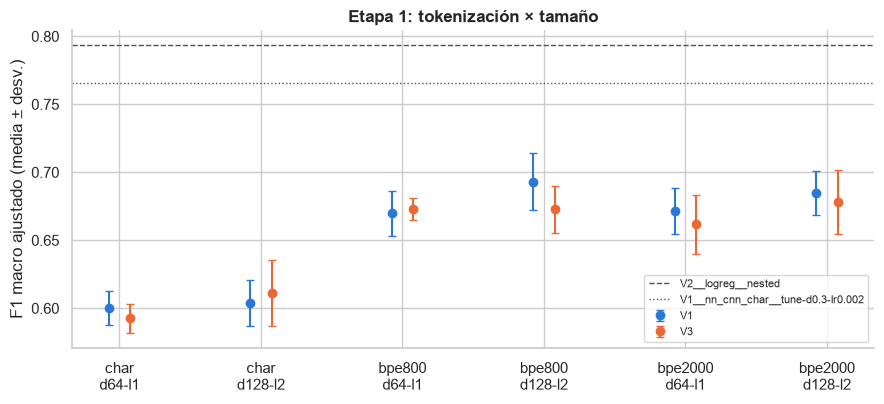

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = [f"{t}\nd{d}-l{l}" for t, d, l in STAGE1]
x = np.arange(len(STAGE1))
for j, v in enumerate(("V1", "V3")):
    vals = [RESULTS[trf_id(v, t, d, l)]["cv"]["tuned"]["F1_macro"] for t, d, l in STAGE1]
    ax.errorbar(x + (j - 0.5) * 0.15, [s.mean() for s in vals], yerr=[s.std() for s in vals], fmt="o", capsize=3,
                color=["#2a78d6", "#eb6834"][j], label=v)
for ref, ls in ((REF_LIN, "--"), (REF_CNN, ":")):
    ax.axhline(REFS[ref]["tuned"]["F1_macro"].mean(), color="#52514e", ls=ls, lw=1, label=ref)
ax.set(xticks=x, xticklabels=labels, ylabel="F1 macro ajustado (media ± desv.)", title="Etapa 1: tokenización × tamaño")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "stage1")
plt.show()

**Interpretación de la etapa 1:**
- **La tokenización es lo único que importa de verdad.**
  - Con BPE, el F1 macro va de 0.662 a 0.693; con caracteres, de 0.593 a 0.611.
  - Con el mismo tamaño (d_model 64, 1 capa), BPE-800 supera a caracteres por 0.070 en V1 y por 0.081 en V3. Son diferencias de 3 a 8 veces la desviación entre folds.
- **El Transformer de caracteres es mucho peor que la CNN de caracteres del `05`** (0.60 frente a 0.765), aunque ve exactamente el mismo texto.
  - La CNN tiene incorporada la idea de que importan los trozos contiguos de 3 a 5 letras. El Transformer tiene que aprenderla desde cero con ≈1.2k tuits, en secuencias de cientos de posiciones, cada una con su propio vector de posición aprendido.
  - No lo consigue: ni siquiera ajusta bien el train (F1 de train 0.645; ver la sección de sobreajuste).
  - Con BPE, cada token ya es una palabra o un trozo frecuente de palabra, y la atención trabaja sobre unidades con significado.
- **El tamaño y el vocabulario no se distinguen del ruido:**
  - d_model 128 con 2 capas supera a 64 con 1 capa por 0.011–0.015 de media entre V1 y V3, una diferencia del orden de la desviación entre folds de cada configuración (0.008–0.024);
  - BPE-800 y BPE-2000 quedan prácticamente iguales (0.683 y 0.682 de media entre V1 y V3, con d_model 128 y 2 capas).
- **V1 queda por delante de V3** en 4 de las 6 configuraciones.
- **Elegida: BPE-800 con d_model 128 y 2 capas, en V1** (0.6930 ± 0.0209). Aun así queda 0.1007 por debajo del mejor lineal y 0.0724 por debajo de la CNN de caracteres, ambas veces "peor" en la comparación pareada.

## 4. Etapa 2: pooling, dropout y aumentación (sobre la mejor configuración)

Sobre la mejor configuración de la etapa 1, y en su mejor variante, cambiamos **una cosa cada vez**:
- **pooling [CLS]** en lugar de la media;
- **dropout 0.3** en lugar de 0.1 (en la red y en la atención);
- **aumentación de datos**, solo en el entrenamiento y nunca en la validación. Cada época, cada carácter se borra, se intercambia con el siguiente o se sustituye con probabilidad 0.05, y además cada token pasa a `[UNK]` con probabilidad 0.1 (*token dropout*). Los tokens `<USER>` y `<URL>` no se tocan.

¿Por qué medir la aumentación? El texto ya trae mucho ruido propio: alargamientos, palabras con letras borradas, faltas (H4, H5). La aumentación podría enseñar robustez a ese ruido o, al contrario, sumar todavía más.

Si dos o más cambios mejoran **de forma consistente** (Δ > su desviación), se prueba también su combinación.

In [7]:
t, d, l = BEST1
STAGE2 = [("-cls", {"pooling": "cls"}), ("-drop0.3", {"dropout": 0.3}), ("-aug", {"augment": True})]
for k, (extra, params) in enumerate(STAGE2, 1):
    run_trf(BEST_VAR, t, d, l, extra, stage="diseño", step=f"{k}/{len(STAGE2)}", **params)
base_id = trf_id(BEST_VAR, t, d, l)
rows = []
improved = {}
for extra, params in STAGE2:
    i = trf_id(BEST_VAR, t, d, l, extra)
    p = paired(i, base_id)
    if p["veredicto"] == "mejor":
        improved[extra] = params
    rows.append({"cambio": extra[1:], "F1 macro": round(RESULTS[i]["cv"]["tuned"]["F1_macro"].mean(), 4),
                 "base": round(RESULTS[base_id]["cv"]["tuned"]["F1_macro"].mean(), 4), **p,
                 "brecha train − val": round(RESULTS[i]["cv"]["train"]["F1_macro"].mean() - RESULTS[i]["cv"]["tuned"]["F1_macro"].mean(), 4)})
if len(improved) >= 2:
    extra = "".join(improved)
    run_trf(BEST_VAR, t, d, l, extra, stage="diseño", step="combinación", **{k: v for p in improved.values() for k, v in p.items()})
    i = trf_id(BEST_VAR, t, d, l, extra)
    rows.append({"cambio": "combinación " + extra, "F1 macro": round(RESULTS[i]["cv"]["tuned"]["F1_macro"].mean(), 4),
                 "base": round(RESULTS[base_id]["cv"]["tuned"]["F1_macro"].mean(), 4), **paired(i, base_id)})
display(pd.DataFrame(rows).set_index("cambio"))

# Mejor configuración: la de la etapa 1 salvo que un cambio sea consistentemente mejor (no se elige dentro del ruido)
candidates = [(base_id, "", {})] + [(trf_id(BEST_VAR, t, d, l, e), e, p) for e, p in improved.items()]
if len(improved) >= 2:
    candidates.append((trf_id(BEST_VAR, t, d, l, "".join(improved)), "".join(improved),
                       {k: v for p in improved.values() for k, v in p.items()}))
BEST_ID, BEST_EXTRA, BEST_PARAMS = max(candidates, key=lambda c: RESULTS[c[0]]["cv"]["tuned"]["F1_macro"].mean())
print(f"Configuración elegida: {BEST_ID} (cambios adoptados: {BEST_EXTRA or 'ninguno'})")
display(summarize([base_id] + [trf_id(BEST_VAR, t, d, l, e) for e, _ in STAGE2]))

[1/3] V1__nn_trf_bpe__v800-d128-l2-cls ... F1 macro 0.6885 ± 0.0266 (semillas: 0.6483–0.6640) | entrenado | 189 s | total 61:10
[2/3] V1__nn_trf_bpe__v800-d128-l2-drop0.3 ... F1 macro 0.6790 ± 0.0228 (semillas: 0.6590–0.6734) | entrenado | 269 s | total 65:39
[3/3] V1__nn_trf_bpe__v800-d128-l2-aug ... F1 macro 0.7052 ± 0.0262 (semillas: 0.6726–0.6892) | entrenado | 377 s | total 71:56


,F1 macro,base,Δ,Δ desv.,folds mejor,veredicto,brecha train − val
cambio,,,,,,,
cls,0.6885,0.693,-0.0044,0.0172,2,empate,0.1064
drop0.3,0.6790,0.693,-0.0140,0.0117,1,peor,0.1198
aug,0.7052,0.693,0.0122,0.0182,3,empate,0.1159


Configuración elegida: V1__nn_trf_bpe__v800-d128-l2 (cambios adoptados: ninguno)


,variante,HS,TR,AG,macro,desv.,micro,micro desv.,macro train,brecha train − val,rango semillas,Δ vs lineal,Δ vs CNN car.,CV (s),tamaño (MB)
model_id,,,,,,,,,,,,,,,
V1__nn_trf_bpe__v800-d128-l2-aug,V1,0.704,0.739,0.672,0.7052,0.0262,0.7021,0.0222,0.8211,0.1159,0.0166,-0.0885 ± 0.0225 (peor),-0.0602 ± 0.0207 (peor),1336,5.85
V1__nn_trf_bpe__v800-d128-l2,V1,0.681,0.736,0.661,0.6930,0.0209,0.6886,0.0212,0.8299,0.1369,0.0038,-0.1007 ± 0.0268 (peor),-0.0724 ± 0.0114 (peor),737,5.85
V1__nn_trf_bpe__v800-d128-l2-cls,V1,0.664,0.748,0.654,0.6885,0.0266,0.6811,0.0263,0.7949,0.1064,0.0157,-0.1051 ± 0.0322 (peor),-0.0768 ± 0.0194 (peor),736,5.85
V1__nn_trf_bpe__v800-d128-l2-drop0.3,V1,0.666,0.727,0.645,0.6790,0.0228,0.6732,0.0237,0.7987,0.1198,0.0145,-0.1147 ± 0.0325 (peor),-0.0864 ± 0.0092 (peor),954,5.85


**Interpretación de la etapa 2:** ningún cambio mejora de forma consistente. Se mantiene la configuración base y no se prueba ninguna combinación.

- **Pooling [CLS]:** −0.0044 ± 0.0172 (2/5 folds), empate. Con tan pocos datos, la media de los tokens es tan buena como aprender a resumir en [CLS], y más simple.
- **Dropout 0.3:** −0.0140 ± 0.0117 (1/5), peor.
  - Apenas reduce la brecha train − validación (0.120 frente a 0.137) y baja el F1 de validación.
  - Regularizar más no arregla el problema; lo que falta es señal.
- **Aumentación:** +0.0122 ± 0.0182 (3/5), empate.
  - Es el F1 macro más alto del notebook (0.7052) y sube las tres etiquetas: HS 0.704 frente a 0.681, TR 0.739 frente a 0.736 y AG 0.672 frente a 0.661.
  - Sin embargo, la variación entre folds es mayor que la ganancia, así que por la regla del empate no se adopta.
  - Además, casi duplica el coste (1336 s de CV frente a 737), porque entrena más épocas antes de parar: mejores épocas entre 8 y 24.
  - Queda registrada (predicciones OOF y de test), por si el `07` quiere usarla.

### Sobreajuste y curvas de aprendizaje

Como en el `05`: F1 en **train** (los ejemplos con los que se ajustaron los pesos), en la **validación interna** (el 12% que elige la época) y en la **validación externa** (OOF), además de las curvas de pérdida por época (fold 0, semilla 0) de las configuraciones de las etapas 1 y 2 en la mejor variante. Si la pérdida de entrenamiento sigue bajando mientras la de validación sube, la red está memorizando.

,train,validación interna,validación externa (OOF),brecha train − OOF,mejores épocas (fold × semilla)
model_id,,,,,
V1__nn_trf_char__d64-l1,0.6444,0.6112,0.6004,0.0440,10 14 14 19 25 11 26 12 11 7 11 9 16 10 8
V1__nn_trf_char__d128-l2,0.6454,0.6275,0.6038,0.0416,6 8 7 5 7 8 10 7 6 5 7 8 6 7 6
V1__nn_trf_bpe__v800-d64-l1,0.7613,0.6762,0.6699,0.0914,9 10 8 13 15 20 11 10 13 13 8 9 12 12 11
V1__nn_trf_bpe__v800-d128-l2,0.8299,0.6981,0.6930,0.1369,5 4 7 5 12 8 8 6 6 10 5 6 7 5 7
V1__nn_trf_bpe__v2000-d64-l1,0.7764,0.6803,0.6715,0.1049,9 8 8 12 13 21 11 8 12 9 11 8 13 12 11
V1__nn_trf_bpe__v2000-d128-l2,0.7893,0.6823,0.6848,0.1045,5 4 5 6 6 8 5 4 4 6 7 6 8 7 7
V1__nn_trf_bpe__v800-d128-l2-cls,0.7949,0.6944,0.6885,0.1064,5 4 5 6 9 6 5 5 4 6 6 6 6 5 5
V1__nn_trf_bpe__v800-d128-l2-drop0.3,0.7987,0.7015,0.6790,0.1198,5 6 5 6 18 10 12 7 9 11 10 8 12 11 11
V1__nn_trf_bpe__v800-d128-l2-aug,0.8211,0.7175,0.7052,0.1159,9 8 24 20 22 10 14 10 22 20 15 21 12 9 13


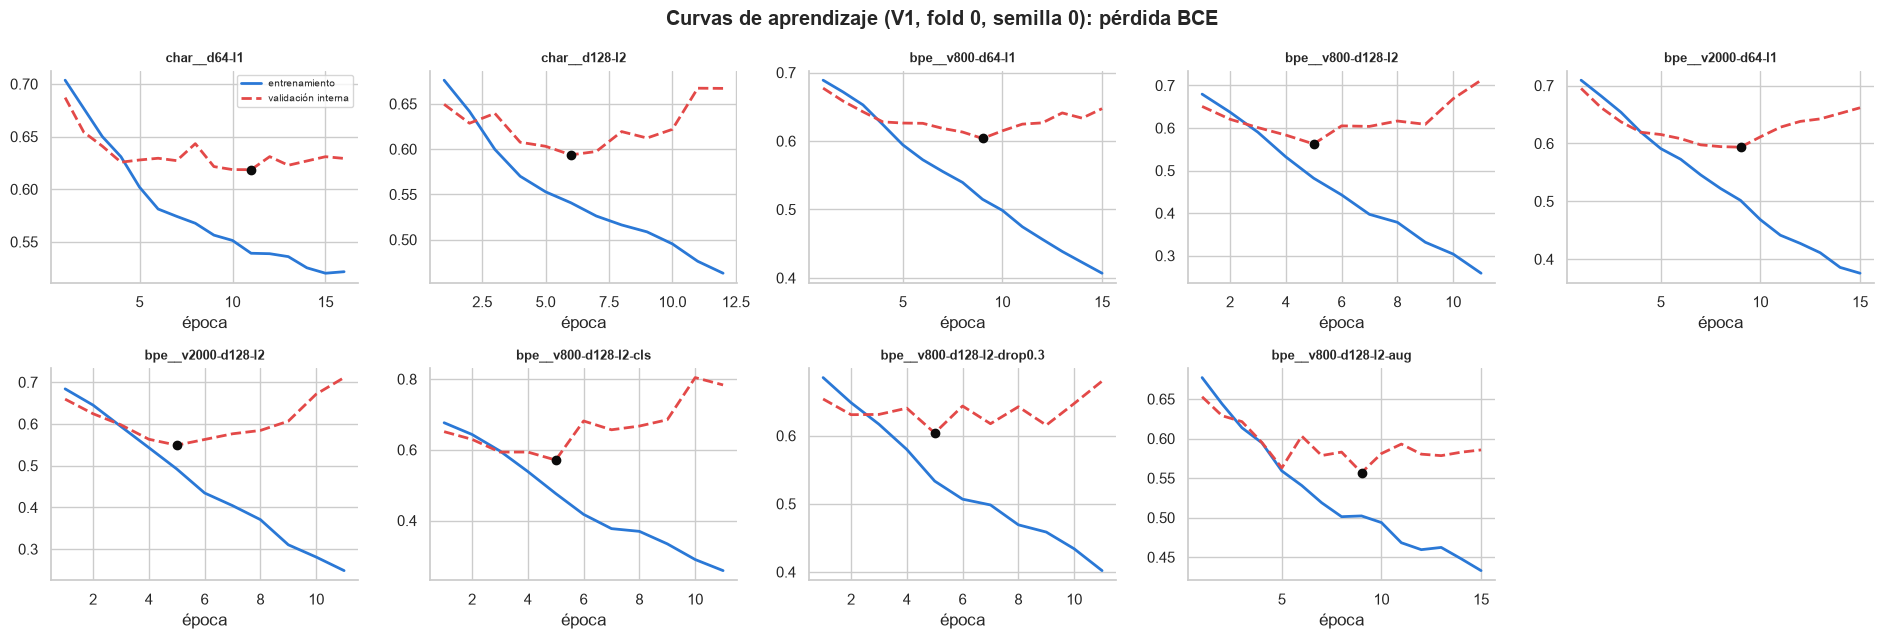

In [8]:
curve_ids = [trf_id(BEST_VAR, tt, dd, ll) for tt, dd, ll in STAGE1] + [trf_id(BEST_VAR, t, d, l, e) for e, _ in STAGE2]
rows = []
for i in curve_ids:
    cv = RESULTS[i]["cv"]
    rows.append({"model_id": i, "train": round(cv["train"]["F1_macro"].mean(), 4),
                 "validación interna": round(cv["inner_val"]["F1_macro"].mean(), 4),
                 "validación externa (OOF)": round(cv["tuned"]["F1_macro"].mean(), 4),
                 "brecha train − OOF": round(cv["train"]["F1_macro"].mean() - cv["tuned"]["F1_macro"].mean(), 4),
                 "mejores épocas (fold × semilla)": " ".join(str(e[0]) for fold in cv["best_epochs"] for e in fold)})
display(pd.DataFrame(rows).set_index("model_id"))

fig, axes = plt.subplots(2, 5, figsize=(19, 6.5))
for ax, i in zip(axes.ravel(), curve_ids):
    c = RESULTS[i]["cv"]["curves"][0][0]
    ep = np.arange(1, len(c["train"]) + 1)
    ax.plot(ep, c["train"], lw=2, color="#2a78d6", label="entrenamiento")
    ax.plot(ep, c["val"], lw=2, ls="--", color="#e34948", label="validación interna")
    b = int(np.argmin(c["val"])) + 1
    ax.plot(b, c["val"][b - 1], "o", color="#0b0b0b")
    ax.set_title(i.replace(f"{BEST_VAR}__nn_trf_", ""), fontsize=9)
    ax.set_xlabel("época")
for ax in axes.ravel()[len(curve_ids):]:
    ax.axis("off")
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"Curvas de aprendizaje ({BEST_VAR}, fold 0, semilla 0): pérdida BCE", fontweight="bold")
fig.tight_layout()
savefig(fig, "learning_curves")
plt.show()

**Interpretación del sobreajuste:**
- **Con BPE hay sobreajuste clásico, que el early stopping corta a tiempo.**
  - El F1 de train es de 0.76–0.83 y el OOF de 0.67–0.69: brecha de 0.09–0.14, mayor con más capacidad (0.09–0.10 con d64-l1 y 0.10–0.14 con d128-l2).
  - En las curvas, la pérdida de validación interna toca su mínimo entre las épocas 5 y 9 y luego sube, mientras la de entrenamiento sigue bajando hasta 0.25–0.41.
  - La brecha es menor que en las CNN y el MLP del `05` (0.16–0.21, H38), pero porque el train se ajusta peor, no porque generalice mejor.
- **Con caracteres el problema es el contrario: subajuste.**
  - El F1 de train es de solo 0.644–0.645 y la brecha de 0.04.
  - La pérdida de validación se estanca en ≈0.62 desde la época 4–6, y la de entrenamiento no baja de 0.46–0.52.
  - La red no encuentra patrones útiles en secuencias tan largas.
- **La validación interna (0.611–0.718) no es optimista frente a la externa (0.600–0.705)**: la época que elige el early stopping es fiable.
- **La aumentación retrasa el sobreajuste:**
  - su pérdida de entrenamiento baja más despacio (≈0.43 en la época 15) y la de validación se mantiene más plana (≈0.56–0.60);
  - por eso sus mejores épocas son más tardías.
  - Es el comportamiento esperado de un regularizador, aunque la ganancia en F1 no supera el ruido.

## 5. Etapa 3: la mejor configuración en las demás variantes

Se corren V0, V1, V2 y V3 (las que falten). V4 es idéntica a V3 por construcción, y V2 (alarg.=1) se recortó por presupuesto (ver la sección 2).

In [9]:
VARS = ["V0", "V1", "V2", "V3"]
todo = [v for v in VARS if trf_id(v, t, d, l, BEST_EXTRA) not in RESULTS]
for k, v in enumerate(todo, 1):
    run_trf(v, t, d, l, BEST_EXTRA, stage="variantes", step=f"{k}/{len(todo)}", **BEST_PARAMS)
var_ids = [trf_id(v, t, d, l, BEST_EXTRA) for v in VARS]
display(summarize(var_ids))
rows = {}
for name, (a, b) in {"V1 − V0 (limpieza)": ("V1", "V0"), "V3 − V2 (restauración)": ("V3", "V2"),
                     "V2 − V1 (alargamientos, risas, censura)": ("V2", "V1")}.items():
    p = paired(trf_id(a, t, d, l, BEST_EXTRA), trf_id(b, t, d, l, BEST_EXTRA))
    rows[name] = f"{p['Δ']:+.4f} ± {p['Δ desv.']:.4f} ({p['folds mejor']}/5, {p['veredicto']})"
display(pd.Series(rows).to_frame("diferencia pareada"))

[1/2] V0__nn_trf_bpe__v800-d128-l2 ... F1 macro 0.6300 ± 0.0108 (semillas: 0.6117–0.6216) | entrenado | 264 s | total 76:21
[2/2] V2__nn_trf_bpe__v800-d128-l2 ... F1 macro 0.6922 ± 0.0176 (semillas: 0.6504–0.6543) | entrenado | 210 s | total 79:51


,variante,HS,TR,AG,macro,desv.,micro,micro desv.,macro train,brecha train − val,rango semillas,Δ vs lineal,Δ vs CNN car.,CV (s),tamaño (MB)
model_id,,,,,,,,,,,,,,,
V1__nn_trf_bpe__v800-d128-l2,V1,0.681,0.736,0.661,0.6930,0.0209,0.6886,0.0212,0.8299,0.1369,0.0038,-0.1007 ± 0.0268 (peor),-0.0724 ± 0.0114 (peor),737,5.85
V2__nn_trf_bpe__v800-d128-l2,V2,0.673,0.747,0.657,0.6922,0.0176,0.6871,0.0182,0.8012,0.1090,0.0039,-0.1015 ± 0.0222 (peor),-0.0732 ± 0.0074 (peor),806,5.85
V3__nn_trf_bpe__v800-d128-l2,V3,0.673,0.711,0.634,0.6728,0.0172,0.6694,0.0216,0.7886,0.1157,0.0129,-0.1208 ± 0.0340 (peor),-0.0925 ± 0.0278 (peor),755,5.86
V0__nn_trf_bpe__v800-d128-l2,V0,0.628,0.651,0.611,0.6300,0.0108,0.6282,0.0082,0.7618,0.1318,0.0099,-0.1637 ± 0.0253 (peor),-0.1354 ± 0.0334 (peor),1003,5.89


,diferencia pareada
V1 − V0 (limpieza),"+0.0630 ± 0.0288 (5/5, mejor)"
V3 − V2 (restauración),"-0.0193 ± 0.0240 (1/5, empate)"
"V2 − V1 (alargamientos, risas, censura)","-0.0008 ± 0.0081 (3/5, empate)"


**Interpretación de las variantes:** V1 (0.6930) ≈ V2 (0.6922) > V3 (0.6728) > V0 (0.6300).
- **La limpieza (V1 − V0) es el mayor efecto de preprocesamiento del proyecto:** +0.0630 ± 0.0288, en 5/5 folds. En el `05` era +0.022 en la CNN de caracteres y +0.047 en la de palabras.
  - Lo más probable es que, sin minúsculas ni limpieza, un BPE de 800 piezas reparta su vocabulario entre variantes de mayúsculas y restos de menciones y URLs.
  - El preprocesamiento importa más cuanto menos datos tiene el modelo para aprender esas equivalencias por sí mismo.
- **La restauración (V3 − V2):** −0.0193 ± 0.0240 (1/5), empate, pero con tendencia negativa, como en la CNN de palabras del `05` (−0.006).
- **Alargamientos, risas y censura (V2 − V1):** −0.0008 ± 0.0081, efecto nulo, como en todos los notebooks anteriores.
- **Variante final: V1.** V4 no se corre porque es idéntica a V3.

## 6. Etapa 4: preentrenamiento MLM

Antes del ajuste con etiquetas, el encoder aprende a **adivinar tokens ocultos**:
- se elige al azar el 15% de los tokens; de ellos, el 80% se cambia por `[MASK]`, el 10% por un token al azar y el 10% se deja igual;
- se entrena con los textos del fold de entrenamiento, **sin etiquetas**, durante 20 o 60 épocas;
- después se ajusta con las etiquetas exactamente igual que antes.

**Por qué esperamos poco.** El MLM funciona cuando hay mucho texto (millones de frases) del que aprender cómo se usan las palabras. Aquí son ≈1.4k tuits por fold, el mismo texto que luego se usa para clasificar. La red puede aprender algo de la "forma" del español de Twitter, pero difícilmente algo que el ajuste supervisado no vea ya. Si no ayuda, lo decimos y no insistimos.

In [10]:
mlm_ids = []
for k, ep in enumerate((20, 60), 1):
    mlm_ids.append(run_trf(BEST_VAR, t, d, l, BEST_EXTRA + f"-mlm{ep}", stage="MLM", step=f"{k}/2",
                           **{**BEST_PARAMS, "mlm_epochs": ep})["model_id"])
best_main = trf_id(BEST_VAR, t, d, l, BEST_EXTRA)
display(pd.DataFrame([{"modelo": i, "F1 macro": round(RESULTS[i]["cv"]["tuned"]["F1_macro"].mean(), 4),
                       "sin MLM": round(RESULTS[best_main]["cv"]["tuned"]["F1_macro"].mean(), 4), **paired(i, best_main),
                       "pérdida MLM (1.ª → última época, fold 0)": f"{RESULTS[i]['cv']['curves'][0][0]['mlm'][0]:.2f} → "
                                                                   f"{RESULTS[i]['cv']['curves'][0][0]['mlm'][-1]:.2f}"}
                      for i in mlm_ids]).set_index("modelo"))

[1/2] V1__nn_trf_bpe__v800-d128-l2-mlm20 ... F1 macro 0.6763 ± 0.0283 (semillas: 0.6376–0.6664) | entrenado | 670 s | total 91:01
[2/2] V1__nn_trf_bpe__v800-d128-l2-mlm60 ... F1 macro 0.6684 ± 0.0122 (semillas: 0.6365–0.6568) | entrenado | 1553 s | total 116:54


,F1 macro,sin MLM,Δ,Δ desv.,folds mejor,veredicto,"pérdida MLM (1.ª → última época, fold 0)"
modelo,,,,,,,
V1__nn_trf_bpe__v800-d128-l2-mlm20,0.6763,0.693,-0.0167,0.0176,1,empate,6.74 → 5.72
V1__nn_trf_bpe__v800-d128-l2-mlm60,0.6684,0.693,-0.0245,0.0133,0,peor,6.79 → 5.28


**Interpretación del MLM:** no ayuda, y cuanto más se preentrena, peor.
- **20 épocas:** −0.0167 ± 0.0176 (1/5), empate.
- **60 épocas:** −0.0245 ± 0.0133 (0/5), peor.
- **La pérdida MLM confirma que se aprende muy poco.**
  - En el fold 0 baja de 6.74 a 5.72 (20 épocas) y de 6.79 a 5.28 (60 épocas). Adivinar al azar entre 800 piezas da ln(800) ≈ 6.68.
  - Al final, el modelo sigue dudando entre unas e^5.28 ≈ 200 piezas: ha aprendido sobre todo qué piezas son frecuentes, y poco del contexto.
- **Por qué empeora (hipótesis):** con ≈1.4k tuits no hay texto suficiente. El encoder sale preparado para predecir piezas frecuentes, y el ajuste con etiquetas tiene que deshacer parte de eso.
- **Coste:** el preentrenamiento multiplica el tiempo de la CV por ≈3 (20 épocas) y por ≈8 (60 épocas); ver `train.log`.
- **Configuración final: sin MLM.** Preentrenar solo tendría sentido con mucho más texto sin etiquetar (la Fase B de la sección 11, que depende de P13).

## 7. Confirmación con `folds_seed2`

La configuración final se vuelve a evaluar con el segundo conjunto de folds (D26), que **solo confirma** y no elige. La referencia lineal se rehace en esos folds con la misma CV anidada del `04` (≈1 min), para tener una comparación pareada. Para la CNN de caracteres solo hay la cifra no pareada del `05` (0.760 en V3 con `folds_seed2`), porque reentrenarla costaría ≈6 min.

In [11]:
# El MLM solo se adopta si mejora de forma consistente; si no, se queda la configuración sin preentrenar
FINAL_ID = max([best_main] + mlm_ids, key=lambda i: (paired(i, best_main)["veredicto"] == "mejor", i == best_main,
                                                      RESULTS[i]["cv"]["tuned"]["F1_macro"].mean()))
print("Configuración final:", FINAL_ID)
fin = RESULTS[FINAL_ID]
conf = run_trf(fin["variant"], fin["tok"], fin["d"], fin["l"], fin["extra"], stage="confirmación", cv_folds=folds2,
               **fin["params"])
LOGREG_GRID = ([{"C": c} for c in (0.3, 1.0, 3.0, 10.0, 30.0)] + [{"C": c, "l1_ratio": 0.5} for c in (1.0, 3.0, 10.0)]
               + [{"C": c, "l1_ratio": 1.0} for c in (3.0, 10.0)])
lin2_cache = CACHE_DIR / "V2__logreg__nested__folds2.pt"
if lin2_cache.exists() and not RECOMPUTE:
    lin2 = {"oof": torch.load(lin2_cache, weights_only=True).numpy()}
else:
    lin2 = {"oof": md.nested_cross_validate("V2", "logreg", "tfidf", LOGREG_GRID, texts, Y, folds2, n_jobs=N_JOBS)["oof"]}
    torch.save(torch.from_numpy(lin2["oof"]), lin2_cache)
lin2["tuned"] = md._summarize_folds(lin2["oof"], Y, folds2)[1]
d2 = conf["cv"]["tuned"]["F1_macro"] - lin2["tuned"]["F1_macro"]
f1m, f12 = fin["cv"]["tuned"]["F1_macro"], conf["cv"]["tuned"]["F1_macro"]
display(pd.DataFrame([
    {"modelo": FINAL_ID, "folds principales": f"{f1m.mean():.4f} ± {f1m.std():.4f}", "folds_seed2": f"{f12.mean():.4f} ± {f12.std():.4f}",
     "Δ vs lineal en folds_seed2": f"{d2.mean():+.4f} ± {d2.std():.4f} ({verdict(d2)})"},
    {"modelo": REF_LIN, "folds principales": f"{REFS[REF_LIN]['tuned']['F1_macro'].mean():.4f}",
     "folds_seed2": f"{lin2['tuned']['F1_macro'].mean():.4f} ± {lin2['tuned']['F1_macro'].std():.4f}", "Δ vs lineal en folds_seed2": "—"},
    {"modelo": REF_CNN + " (05, V3, no pareada)", "folds principales": "0.7654 (V1)", "folds_seed2": "0.7601 (V3)",
     "Δ vs lineal en folds_seed2": "—"}]).set_index("modelo"))

Configuración final: V1__nn_trf_bpe__v800-d128-l2
[·] V1__nn_trf_bpe__v800-d128-l2__folds2 ... F1 macro 0.6768 ± 0.0382 (semillas: 0.6436–0.6727) | entrenado | 180 s | total 119:54


,folds principales,folds_seed2,Δ vs lineal en folds_seed2
modelo,,,
V1__nn_trf_bpe__v800-d128-l2,0.6930 ± 0.0209,0.6768 ± 0.0382,-0.1089 ± 0.0377 (peor)
V2__logreg__nested,0.7937,0.7856 ± 0.0178,—
"V1__nn_cnn_char__tune-d0.3-lr0.002 (05, V3, no pareada)",0.7654 (V1),0.7601 (V3),—


**Interpretación de la confirmación:** `folds_seed2` confirma el orden lineal > CNN de caracteres > Transformer.
- **El Transformer baja de 0.6930 a 0.6768**, dentro de su desviación (± 0.0382).
- **El lineal da 0.7856 ± 0.0178,** la misma cifra que en H43.
- **La diferencia pareada es de −0.1089 ± 0.0377:** peor, igual que en los folds principales (−0.1007).
- **La CNN de caracteres (0.7601, no pareada) también queda muy por encima.**
- **La desviación entre folds del Transformer casi se duplica** (0.038 frente a 0.021): es más sensible a la partición que los otros modelos.

## 8. Ruido por semilla

El rango del F1 macro entre las 3 semillas de cada configuración (cada semilla evaluada por separado, con el mismo protocolo) y la ganancia de promediarlas.

In [12]:
rows = []
for i, r in RESULTS.items():
    if "folds2" in i:
        continue
    s = [x["F1_macro"].mean() for x in r["cv"]["tuned_per_seed"]]
    rows.append({"model_id": i, **{f"semilla {j + 1}": round(v, 4) for j, v in enumerate(s)},
                 "rango": round(max(s) - min(s), 4), "promedio de 3": round(r["cv"]["tuned"]["F1_macro"].mean(), 4),
                 "ganancia del promedio": round(r["cv"]["tuned"]["F1_macro"].mean() - np.mean(s), 4)})
seeds_t = pd.DataFrame(rows).set_index("model_id").sort_values("promedio de 3", ascending=False)
display(seeds_t)
print(f"Rango entre semillas: mediana {seeds_t['rango'].median():.4f}, máximo {seeds_t['rango'].max():.4f} | "
      f"ganancia del promedio: mediana {seeds_t['ganancia del promedio'].median():+.4f}")

,semilla 1,semilla 2,semilla 3,rango,promedio de 3,ganancia del promedio
model_id,,,,,,
V1__nn_trf_bpe__v800-d128-l2-aug,0.6880,0.6726,0.6892,0.0166,0.7052,0.0219
V1__nn_trf_bpe__v800-d128-l2,0.6553,0.6527,0.6565,0.0038,0.6930,0.0381
V2__nn_trf_bpe__v800-d128-l2,0.6504,0.6505,0.6543,0.0039,0.6922,0.0404
V1__nn_trf_bpe__v800-d128-l2-cls,0.6591,0.6483,0.6640,0.0157,0.6885,0.0314
V1__nn_trf_bpe__v2000-d128-l2,0.6619,0.6459,0.6554,0.0160,0.6848,0.0304
V1__nn_trf_bpe__v800-d128-l2-drop0.3,0.6590,0.6734,0.6665,0.0145,0.6790,0.0127
V3__nn_trf_bpe__v2000-d128-l2,0.6230,0.6566,0.6546,0.0336,0.6782,0.0335
V1__nn_trf_bpe__v800-d128-l2-mlm20,0.6376,0.6664,0.6463,0.0288,0.6763,0.0262
V3__nn_trf_bpe__v800-d64-l1,0.6493,0.6460,0.6437,0.0056,0.6732,0.0269


Rango entre semillas: mediana 0.0138, máximo 0.0336 | ganancia del promedio: mediana +0.0269


**Interpretación del ruido por semilla:**
- **Promediar semillas aporta mucho más que en el `05`.**
  - Cada semilla de la configuración final da 0.6527–0.6565 (rango 0.0038), pero el promedio de las 3 da 0.6930: +0.0381.
  - En el conjunto de configuraciones, la mediana del rango es 0.0138 (máximo 0.0336) y la mediana de la ganancia, +0.0269. En el `05` la ganancia mediana era +0.006 (H40).
- **Qué significa:** cada Transformer, por separado, es débil y se equivoca en tuits distintos según la semilla, y al promediar sus probabilidades esos errores se compensan. Es la firma de un modelo con mucha varianza.
- **Más semillas (5 o 10) probablemente subirían algo más el F1,** pero no se prueba por presupuesto. Aun así, no cerraría una distancia de 0.10 con el lineal.
- **Excepción, los Transformers de caracteres:** casi no ganan con el promedio (de −0.0025 a +0.019), porque todos subajustan de la misma manera.
- **Para comparar configuraciones,** diferencias menores que ≈0.014 están dentro del ruido de semilla.

## 9. Complementariedad con el mejor lineal y con la CNN de caracteres

Con las decisiones OOF (umbral elegido en los otros folds y jerarquía) medimos dos cosas:
- la **correlación de errores** del Transformer final con el mejor lineal y con la CNN de caracteres;
- el **% de tuits** en que uno acierta las tres etiquetas y el otro no.

**Criterio para el `07`:** entra si su F1 está a **menos de 0.04 del mejor lineal** y su **correlación de errores con él es < 0.65**.

In [13]:
def crossfit_pred(oof):
    pred = np.zeros_like(Y)
    for k in sorted(folds.unique()):
        val = (folds == k).to_numpy()
        pred[val] = md.apply_decision(oof[val], md.best_thresholds(Y[~val], oof[~val]), hierarchy=True)
    return pred


# El Transformer final y los 4 mejores del resto (otras tokenizaciones o tamaños) para comparar
others = sorted([i for i in RESULTS if "folds2" not in i and i != FINAL_ID],
                key=lambda i: -RESULTS[i]["cv"]["tuned"]["F1_macro"].mean())
cands = [FINAL_ID] + others[:4]
rows = []
for ref in (REF_LIN, REF_CNN):
    ref_pred = crossfit_pred(REFS[ref]["oof"])
    ref_ok = (ref_pred == Y).all(axis=1)
    for i in cands:
        pred = crossfit_pred(RESULTS[i]["cv"]["oof"])
        ok = (pred == Y).all(axis=1)
        f1 = RESULTS[i]["cv"]["tuned"]["F1_macro"].mean()
        corr = np.corrcoef((pred != Y).ravel(), (ref_pred != Y).ravel())[0, 1]
        rows.append({"transformer": i, "frente a": ref, "F1 macro": round(f1, 4), "correlación de errores": round(corr, 3),
                     "% transformer acierta y el otro falla": round(100 * np.mean(ok & ~ref_ok), 1),
                     "% el otro acierta y transformer falla": round(100 * np.mean(ref_ok & ~ok), 1)})
comp = pd.DataFrame(rows).set_index(["transformer", "frente a"])
display(comp)
lin_f1 = REFS[REF_LIN]["tuned"]["F1_macro"].mean()
fin_row = comp.loc[(FINAL_ID, REF_LIN)]
ENTRA = bool(lin_f1 - fin_row["F1 macro"] < 0.04 and fin_row["correlación de errores"] < 0.65)
print(f"Criterio para el 07 con {FINAL_ID}: distancia al mejor lineal {lin_f1 - fin_row['F1 macro']:.4f} (< 0.04) y "
      f"correlación de errores {fin_row['correlación de errores']:.3f} (< 0.65) -> {'ENTRA' if ENTRA else 'NO ENTRA'}")

,,F1 macro,correlación de errores,% transformer acierta y el otro falla,% el otro acierta y transformer falla
transformer,frente a,,,,
V1__nn_trf_bpe__v800-d128-l2,V2__logreg__nested,0.6930,0.450,7.3,17.2
V1__nn_trf_bpe__v800-d128-l2-aug,V2__logreg__nested,0.7052,0.434,6.9,19.9
V2__nn_trf_bpe__v800-d128-l2,V2__logreg__nested,0.6922,0.442,7.6,16.2
V1__nn_trf_bpe__v800-d128-l2-cls,V2__logreg__nested,0.6885,0.412,7.5,21.1
V1__nn_trf_bpe__v2000-d128-l2,V2__logreg__nested,0.6848,0.364,6.0,24.4
V1__nn_trf_bpe__v800-d128-l2,V1__nn_cnn_char__tune-d0.3-lr0.002,0.6930,0.454,9.2,15.7
V1__nn_trf_bpe__v800-d128-l2-aug,V1__nn_cnn_char__tune-d0.3-lr0.002,0.7052,0.481,7.9,17.3
V2__nn_trf_bpe__v800-d128-l2,V1__nn_cnn_char__tune-d0.3-lr0.002,0.6922,0.458,9.5,14.6
V1__nn_trf_bpe__v800-d128-l2-cls,V1__nn_cnn_char__tune-d0.3-lr0.002,0.6885,0.465,8.3,18.4


Criterio para el 07 con V1__nn_trf_bpe__v800-d128-l2: distancia al mejor lineal 0.1007 (< 0.04) y correlación de errores 0.450 (< 0.65) -> NO ENTRA


**Interpretación de la complementariedad:**
- **Los errores son realmente distintos.** La correlación de errores del Transformer final es de 0.450 con el mejor lineal y de 0.454 con la CNN de caracteres. Son las más bajas del proyecto: en el `05`, entre las redes y el lineal iban de 0.50 a 0.61 (H42).
- **Pero el reparto es muy asimétrico:**
  - el Transformer acierta las tres etiquetas en el 7.3% de los tuits que el lineal falla, y falla en el 17.2% de los que el lineal acierta;
  - frente a la CNN, 9.2% y 15.7%.
  - Parte de la baja correlación viene, simplemente, de que se equivoca mucho más.
- **Criterio para el `07`: NO ENTRA.** La correlación (0.450) cumple el umbral de 0.65, pero la distancia al mejor lineal (0.1007) está muy lejos de 0.04. Ni siquiera la versión con aumentación (0.7052) se acerca: queda a 0.0885.
- **La diversidad de un modelo débil rara vez mejora un promedio.** Para el `07` no se fuerza.

## 10. ¿A qué tokens atiende? (6 ejemplos)

Para 3 tuits bien clasificados y 3 mal clasificados del fold de validación, mostramos los 5 tokens con más peso de atención en la última capa (media de cabezas y de las 3 semillas):
- con pooling por media, la atención **recibida** por cada token;
- con [CLS], la atención del token [CLS].

Se usan los modelos de cada fold, que nunca vieron esos tuits.

**Aviso:** la atención no es una explicación causal. Indica dónde "mira" la capa, no qué tokens decidieron la predicción. Con tokenización por caracteres, además, los tokens son letras sueltas y es menos interpretable.

In [14]:
best = RESULTS[best_main]
pred = crossfit_pred(best["cv"]["oof"])
ok = (pred == Y).all(axis=1)
rng = np.random.default_rng(SEED)
picks = list(rng.choice(np.where(ok & (Y.sum(1) > 0))[0], 3, replace=False)) + list(rng.choice(np.where(~ok)[0], 3, replace=False))
rows = []
for idx in picks:
    k = folds.iloc[idx]
    model = best["cv"]["models"][sorted(folds.unique()).index(k)]
    att = [(tok, w) for tok, w in model.attention(texts.iloc[[idx]])[0] if tok not in ("[CLS]", "[PAD]")]
    top = sorted(att, key=lambda x: -x[1])[:5]
    rows.append({"caso": "acierta" if ok[idx] else "falla", "texto": texts.iloc[idx][:100],
                 "real": "".join(map(str, Y[idx])), "predicho": "".join(map(str, pred[idx])),
                 "tokens con más atención": ", ".join(f"{repr(tk)} ({w:.3f})" for tk, w in top)})
display(pd.DataFrame(rows))

,caso,texto,real,predicho,tokens con más atención
0,acierta,la pedroche que buena est y que feminista es pero la chica de tu barrio que lleva esco...,111,111,"'▁tu' (0.038), '▁pe' (0.032), '▁est' (0.028), 'che' (0.027), 'min' (0.025)"
1,acierta,@Stolbizer @mainesCyN Callate la boca perra siberiana metiendo a CFK en esto! Sos tan ...,111,111,"'▁perra' (0.086), '▁callate' (0.038), 'i' (0.031), '▁boca' (0.029), '<USER>' (0.028)"
2,acierta,@SenoraletiLeti @pollaprecoz1 Callate y aprieta esas naglotas tuyas perra blanca~,111,111,"'▁tu' (0.083), '<USER>' (0.062), '▁es' (0.051), 'ri' (0.048), '▁perra' (0.046)"
3,falla,Grabenselo en la cabeza Baekhyun no es ninguna gata ni puta ni zorra ni es mujer es ho...,000,101,"'▁zorra' (0.046), 'be' (0.041), '▁ba' (0.032), '▁puta' (0.031), 'se' (0.030)"
4,falla,Y las ves llorando x un amor de dos dias y tu k has sufrido x aos callada como una put...,111,101,"'▁tu' (0.029), '▁l' (0.025), 'lo' (0.024), '▁x' (0.024), 'do' (0.024)"
5,falla,@DeVatso @pablocasado_ Ojal mandemos a frica cientos de barcos con esta gente y traiga...,000,101,"'.' (0.044), '▁f' (0.040), 'ca' (0.036), '▁o' (0.036), '▁de' (0.035)"


**Interpretación de la atención** (recordatorio: no es causal):
- **Aciertos 1 y 2:** la atención se concentra en `▁perra` (0.086 y 0.046), `▁callate` y `<USER>`. Son el insulto, el imperativo y la mención a la persona, coherentes con HS + TR + AG (agresión dirigida a alguien concreto, H16).
- **Acierto 0:** la atención está repartida entre fragmentos (`▁tu` 0.038, `▁pe` y `che` de *pedroche*), con pesos de ≈0.03, casi uniformes. Acierta, pero sin un foco claro.
- **Errores 3 y 5:** falsos positivos de HS y AG (predice 101 en tuits etiquetados 000).
  - En el 3, la atención va a `▁zorra` (0.046) y `▁puta` (0.031): el tuit usa los insultos para *defender* a alguien, y el modelo reacciona a la palabra, igual que un modelo lineal.
  - En el 5 (*mandemos a frica cientos de barcos…*, sin la *Á* por el borrado de no ASCII), la atención se reparte entre `.`, `▁f` y `ca`, y no se ve nada interpretable.
- **Error 4:** falla TR (predice 101 en un 111) con una atención casi uniforme (≤ 0.029).
- **En conjunto:** cuando hay un insulto explícito, la atención lo encuentra. Pero esto no añade nada que el lineal no capture ya con sus n-gramas, y en los tuits sin palabras clave la atención no muestra ninguna estructura.

## 11. Fase B (solo documentada, no ejecutada): preentrenar con más texto

El MLM de la sección 6 solo puede usar ≈1.4k tuits. Con más texto sin etiquetas el preentrenamiento podría aprender algo útil. **No se ha hecho nada de esto**; esto es lo que haría falta:

1. **Autorización del profesor (P13).** Hay dos fuentes posibles, y ninguna se usa sin permiso explícito:
   - **el texto del test** (1154 tuits, sin etiquetas): es aprendizaje transductivo;
   - **un corpus externo de tuits en español.** Si el corpus de la competencia deriva de HatEval (P4), un corpus externo podría contener los tuits del test, así que habría que comprobarlo.
2. **Licencia verificada en la fuente** del corpus y **cita** en `PROGRESO.md` §9 antes de usarlo.
3. **El mismo borrado de caracteres no ASCII que tiene el train** (D3): `preprocessing.remove_non_ascii` antes de cualquier otro paso. Si no, el modelo aprendería tildes y ñ que nunca verá en la competencia.
4. **Protocolo sin fugas:**
   - el BPE y el MLM se entrenan con el corpus externo (y, si se autoriza, con el test), nunca con el fold de validación;
   - el ajuste con etiquetas sigue dentro de cada fold;
   - el corpus no puede contener tuits del train ni del test, salvo que se use el test con autorización.
5. **Coste estimado:** cada época de MLM sobre 1.4k tuits con la configuración final cuesta lo medido en la sección 2. El tiempo crece en proporción al número de textos: con 100 000 tuits serían ≈70 veces más por época. Eso son varias horas en CPU, o bien un corpus más pequeño o una GPU.

## 12. Guardado y comprobaciones

- **Registro:** todos los Transformers evaluados con los folds principales se añaden a `models/registry.csv` (familia `transformer`) y a los parquet de predicciones OOF y de test (media de las 3 semillas, sin calibrar).
- **Archivos:** se guardan en `models/06_transformer/` (`.pt` + `.json`) la configuración final en todas sus variantes, las configuraciones de la etapa 1 en la mejor variante y las de MLM. Todos los modelos finales están además en la caché.
- **Prueba de carga:** las probabilidades desde disco deben coincidir con las de memoria (tolerancia 1e-5).
- **Comprobación de reglas:** `grep` sobre `notebooks/` de cualquier carga de pesos o tokenizadores preentrenados.

In [15]:
to_save = set(var_ids) | set(mlm_ids) | {trf_id(BEST_VAR, tt, dd, ll) for tt, dd, ll in STAGE1}
rows, oof_frames, test_frames, checks = [], [], [], []
for mid, r in RESULTS.items():
    if "model" not in r:
        continue
    model, cv = r["model"], r["cv"]
    saved = mid in to_save
    if saved:
        meta = {"notebook": "06", "stage": r["stage"],
                "cv": {s: {m: {"mean": float(cv[s][m].mean()), "std": float(cv[s][m].std())} for m in cv[s].columns}
                       for s in ("at_05", "tuned", "train", "inner_val")},
                "best_epochs_cv": cv["best_epochs"], "seed_f1_macro": [float(s["F1_macro"].mean()) for s in cv["tuned_per_seed"]],
                "cv_folds_file": "data/processed/folds.csv", "n_train": len(train),
                "thresholds_source": "F1 máximo sobre todas las OOF de la CV"}
        path = nn_.save_transformer_model(model, mid, meta)
        reloaded = md.load_model(path)
        checks.append({"model_id": mid, "archivo": f"{path.parent.name}/{path.name}",
                       "máx. diferencia de probabilidad": float(np.abs(reloaded.predict_proba(test["text"]) - r["test_proba"]).max())})
    extra = {"architecture": md.CLASSIFIER_NAMES[model.classifier], "seeds": model.n_seeds, "epochs": model.fixed_epochs,
             "train_seconds": round(model.train_seconds_, 1)}
    rows.append(md.registry_row(mid, model, cv, notebook="06", saved=saved, size_mb=r["size_mb"], extra=extra))
    oof_frames.append(md.prediction_frame(mid, train["id"], cv["oof"], fold=folds, calibrated=False))
    test_frames.append(md.prediction_frame(mid, test["id"], r["test_proba"], pred=r["test_pred"], calibrated=False))
registry = md.update_registry(rows)
md.update_predictions(oof_frames, md.OOF_PATH)
md.update_predictions(test_frames, md.TEST_PRED_PATH)
checks = pd.DataFrame(checks).set_index("model_id")
display(checks)
assert (checks["máx. diferencia de probabilidad"] <= 1e-5).all()
print(f"Registro: {len(registry)} modelos ({(registry['notebook'] == '06').sum()} del 06) | guardados: {len(checks)}")

,archivo,máx. diferencia de probabilidad
model_id,,
V1__nn_trf_char__d64-l1,06_transformer/V1__nn_trf_char__d64-l1.pt,0.0
V1__nn_trf_char__d128-l2,06_transformer/V1__nn_trf_char__d128-l2.pt,0.0
V1__nn_trf_bpe__v800-d64-l1,06_transformer/V1__nn_trf_bpe__v800-d64-l1.pt,0.0
V1__nn_trf_bpe__v800-d128-l2,06_transformer/V1__nn_trf_bpe__v800-d128-l2.pt,0.0
V1__nn_trf_bpe__v2000-d64-l1,06_transformer/V1__nn_trf_bpe__v2000-d64-l1.pt,0.0
V1__nn_trf_bpe__v2000-d128-l2,06_transformer/V1__nn_trf_bpe__v2000-d128-l2.pt,0.0
V3__nn_trf_bpe__v800-d128-l2,06_transformer/V3__nn_trf_bpe__v800-d128-l2.pt,0.0
V0__nn_trf_bpe__v800-d128-l2,06_transformer/V0__nn_trf_bpe__v800-d128-l2.pt,0.0
V2__nn_trf_bpe__v800-d128-l2,06_transformer/V2__nn_trf_bpe__v800-d128-l2.pt,0.0


Registro: 185 modelos (19 del 06) | guardados: 11


In [16]:
# Comprobación de reglas: ninguna carga de modelos, pesos o tokenizadores preentrenados en el código del proyecto.
# El patrón se construye por partes para que esta celda no se encuentre a sí misma.
banned = ["from" + "_pretrained", "Auto" + "Model", "Auto" + "Tokenizer", "import " + "transformers", "from " + "transformers"]
py_files = sorted(str(p) for p in NOTEBOOKS_DIR.glob("*.py"))
grep = subprocess.run(["grep", "-n", "-E", "|".join(banned), *py_files], capture_output=True, text=True)
print(f"grep -n -E '{'|'.join(banned)}' notebooks/*.py -> código de salida {grep.returncode} "
      f"({'sin coincidencias' if grep.returncode == 1 else grep.stdout})")
hits = []
for nb_path in sorted(NOTEBOOKS_DIR.glob("*.ipynb")):  # en los notebooks, solo el código (el markdown cita las reglas)
    for c in nbformat.read(nb_path, 4).cells:
        if c.cell_type == "code" and re.search("|".join(banned), c.source):
            hits.append(nb_path.name)
print("Celdas de código de notebooks con coincidencias:", sorted(set(hits)) or "ninguna")
print("Librería `transformers` instalada en el entorno:", importlib.util.find_spec("transformers") is not None)

grep -n -E 'from_pretrained|AutoModel|AutoTokenizer|import transformers|from transformers' notebooks/*.py -> código de salida 1 (sin coincidencias)
Celdas de código de notebooks con coincidencias: ninguna
Librería `transformers` instalada en el entorno: False


**Comprobaciones:**
- **Modelos guardados:** 11 en `models/06_transformer/`, cada uno con su `.pt` y su `.json`:
  - las 6 configuraciones de la etapa 1 en V1;
  - la configuración final en V0, V2 y V3 (V1 ya está entre las anteriores);
  - las 2 de MLM.
  - Al recargarlos desde disco, la diferencia máxima de probabilidad es 0.0 en todos (tolerancia 1e-5).
- **Registro:** 185 modelos, 19 de ellos del `06` (12 + 3 + 2 + 2). Todos tienen predicciones OOF y de test (media de 3 semillas). La ejecución de `folds_seed2` solo confirma y no se registra.
- **Reglas:**
  - `grep` sobre `notebooks/*.py` termina con código de salida 1 (sin coincidencias), y ninguna celda de código de los notebooks contiene `from_pretrained`, `AutoModel`, `AutoTokenizer` ni importaciones de `transformers`;
  - la librería `transformers` ni siquiera está instalada;
  - solo se usan `torch.nn` con pesos aleatorios y el entrenador BPE de `tokenizers`, ajustado dentro de cada fold.

## 13. Conclusiones

**Resultado** (F1 ajustado + jerarquía, media ± desviación entre folds; Δ pareados por fold):

| Modelo | HS | TR | AG | F1 macro | F1 micro | Δ vs lineal | Δ vs CNN de caracteres |
|---|---|---|---|---|---|---|---|
| **Transformer final** `V1__nn_trf_bpe__v800-d128-l2` | 0.681 | 0.736 | 0.661 | 0.693 ± 0.021 | 0.689 | −0.101 ± 0.027 (peor) | −0.072 ± 0.011 (peor) |
| Transformer + aumentación `…-aug` (empate con el final) | 0.704 | 0.739 | 0.672 | 0.705 ± 0.026 | 0.702 | −0.089 ± 0.023 (peor) | −0.060 ± 0.021 (peor) |
| Mejor Transformer de caracteres `V3__nn_trf_char__d128-l2` | 0.622 | 0.627 | 0.584 | 0.611 ± 0.025 | 0.612 | −0.183 ± 0.023 (peor) | −0.154 ± 0.026 (peor) |
| CNN de caracteres del `05` | 0.767 | 0.800 | 0.730 | 0.765 ± 0.024 | 0.762 | — | — |
| Mejor lineal del `04` (`V2__logreg__nested`) | 0.786 | 0.833 | 0.762 | 0.794 ± 0.022 | 0.790 | — | — |

En `folds_seed2`: Transformer 0.677 ± 0.038 frente al lineal 0.786 (−0.109, peor).

1. **Un Transformer desde cero no compite con ≈1.4k tuits.** Queda 0.10 por debajo del lineal y 0.07 por debajo de la CNN de caracteres, con la diferencia repartida por igual entre las tres etiquetas. `folds_seed2` lo confirma. Era el resultado esperado: sin preentrenamiento, la autoatención no tiene de dónde aprender.
2. **Qué decisiones importaron:**
   - la **tokenización**: BPE frente a caracteres, +0.07–0.08. Por caracteres la red subajusta (F1 de train 0.645);
   - la **limpieza** (V1 − V0): +0.063 en 5/5 folds, el mayor efecto de preprocesamiento del proyecto;
   - **promediar 3 semillas**: +0.038.
3. **Qué no importó:**
   - en empate: el tamaño (d64-l1 frente a d128-l2), el vocabulario (800 frente a 2000), el pooling (media frente a [CLS]), la aumentación (+0.012) y la restauración (V3);
   - peor: el dropout 0.3 y el preentrenamiento MLM, que empeora más cuanto más dura (−0.017 y −0.025).
4. **Diversidad:** sus errores son los menos correlacionados del proyecto (0.45 con el lineal y con la CNN), pero falla más del doble de lo que acierta donde el lineal falla (17.2% frente a 7.3%). Según el criterio (F1 a menos de 0.04 del lineal y correlación < 0.65), **no entra en el ensamble del `07`**.
5. **Para el `07`:** no hay que cambiar nada de D25. El ensamble se construye con los lineales, las CNN del `05` y los árboles. El Transformer y su versión con aumentación quedan registrados (predicciones OOF y de test), pero no se llevan al ensamble.
6. **La única vía con margen real** sería preentrenar con mucho más texto sin etiquetar (Fase B), y eso depende de P13. Con el texto del fold, el MLM ya mostró que no aporta.